# 09-ADC与传感器采集

> 从模拟电压到可信的温度：先采到正确的数据，再按电路和器件特性换算，最后处理噪声、故障与时间有效性。

这是「嵌入式单片机一套通关」十二篇笔记的第 09 篇，承接 GPIO、中断与定时器、DMA，以及第 08 篇的通信与驱动分层。本篇串起 **采样与量化 → GD32 ADC 配置 → 单通道与多通道采集 → 定时触发与 DMA → 电位器、内部通道与 NTC → DHT11 数字温湿度采集**。

学完应能回答：12 位 ADC 有多少个码？4095 和 4096 在换算中各表示什么？ADC 时钟、采样时间和采样频率有什么区别？扫描是否等于同时采样？DMA 内存里的数据什么时候能读？NTC 为什么不能直接按电压线性换算？DHT11 为什么不用 MCU 的 ADC？


## 1. 本篇范围、示例平台与阅读顺序

| 课程页面 | 本篇内容 |
|---|---|
| GD32F4之ADC查询 | 外部通道、引脚与 ADC0 内部通道 |
| ADC、ADC系统工作原理 | 模拟/数字、采样量化、SAR、工作模式、对齐与校准 |
| ADC开发 | 电位器、芯片温度、单次、多通道、连续与 DMA |
| 练习-热敏电阻 | PA1 分压电路、电阻换算、阻温查表 |
| 温湿度传感器DHT11 | 单线时序、40 位帧、校验、温湿度数据与驱动 |
| 官方手册补充 | EOC、扫描结果搬运、数据溢出、低分辨率布局、内部通道与过采样 |

资料来自[用户提供的知识库](https://www.yuque.com/embheima/mcu)，当前公开库为[嵌入式单片机一套通关](https://www.yuque.com/xxcls/mcu)。本篇阅读了上述 **6 个课程页面的可访问正文与可见短代码**，视觉核对了 NTC 原理图及 DHT11 接线/时序表，并读取 GD32F4xx User Manual 3.4 的 ADC 章节。网页长代码编辑器和完整工程未全部展开/下载。

示例沿用 **GD32F407VET6、匹配 GD32F4xx SPL/CMSIS、C99**。系列手册中的最高速率、模块数量和功能应再落实到实际芯片数据手册。课程部分框图带“注入组”或不同版本的结构，本篇采用已核对的常规序列，避免把别的平台 API 混进当前配置。

代码分为独立算法、厂商库配置片段和应用接口约定。`app_*`、`board_*` 不是芯片库自带函数；需要工程适配的片段会说明前提。3 张图为自绘学习示意。

阅读路线：第 2～10 节建立 ADC 原理，第 11～19 节学习 GD32 采集，第 20～24 节完成模拟传感器换算，第 25～28 节学习 DHT11，最后做系统整合与自测。

**本篇未进行 SDK 编译、烧录、上板运行或电气测量。** 电脑复核用于检查文档与算法，实物仍需按最后的实验步骤验收。


## 2. 模拟传感器与数字传感器：输出接口不同

传感器把温度、光照、压力等物理量转换成可处理信号。MCU 获取信号的方式取决于输出接口。

| 输出形式 | MCU 获取方式 | 例子 | 换算重点 |
|---|---|---|---|
| 模拟电压 | ADC 采样 | 电位器、模拟温度/光照输出 | 电压范围、参考、传感器传递函数 |
| 电阻 | 激励与分压后 ADC | NTC、某些电阻式探头 | 电路位置、阻值、阻温曲线、自热 |
| 数字寄存器 | I2C/SPI 等 | 数字加速度/温度芯片 | 协议、有效位、量程、端序、状态 |
| 单线脉宽数据 | GPIO 时序或定时捕获 | DHT11 | 启动与响应、位宽、校验、采集间隔 |

NTC 本身是温度相关电阻，先经过电路形成电压，MCU 再采集。DHT11 模块内部完成感测和数字化，MCU 收到的是数字帧，**不能把 DATA 接到 ADC 后按电压推算温度**。

模组通常由传感元件、处理芯片、电源/接口电路等组成，外部看起来是一个器件。设计自己的模组，需要同时考虑传感特性、校准、安装、供电、接口、量产一致性和数据有效性。

一个数字读数也可能来自旧测量、断线默认值或错误帧；一个稳定的模拟码也可能来自饱和、短路或错误参考。完整采集必须回答 **值是多少、单位是什么、何时采得、是否有效**。


## 3. ADC 的三个动作：采样、量化、编码

模拟信号在时间和幅值上连续。数字化需要分别处理这两个维度。

1. **采样：** 在选定时刻取得输入电压，时间变成离散。
2. **量化：** 把电压映射到有限的幅值等级。
3. **编码：** 用二进制数表示所属等级。

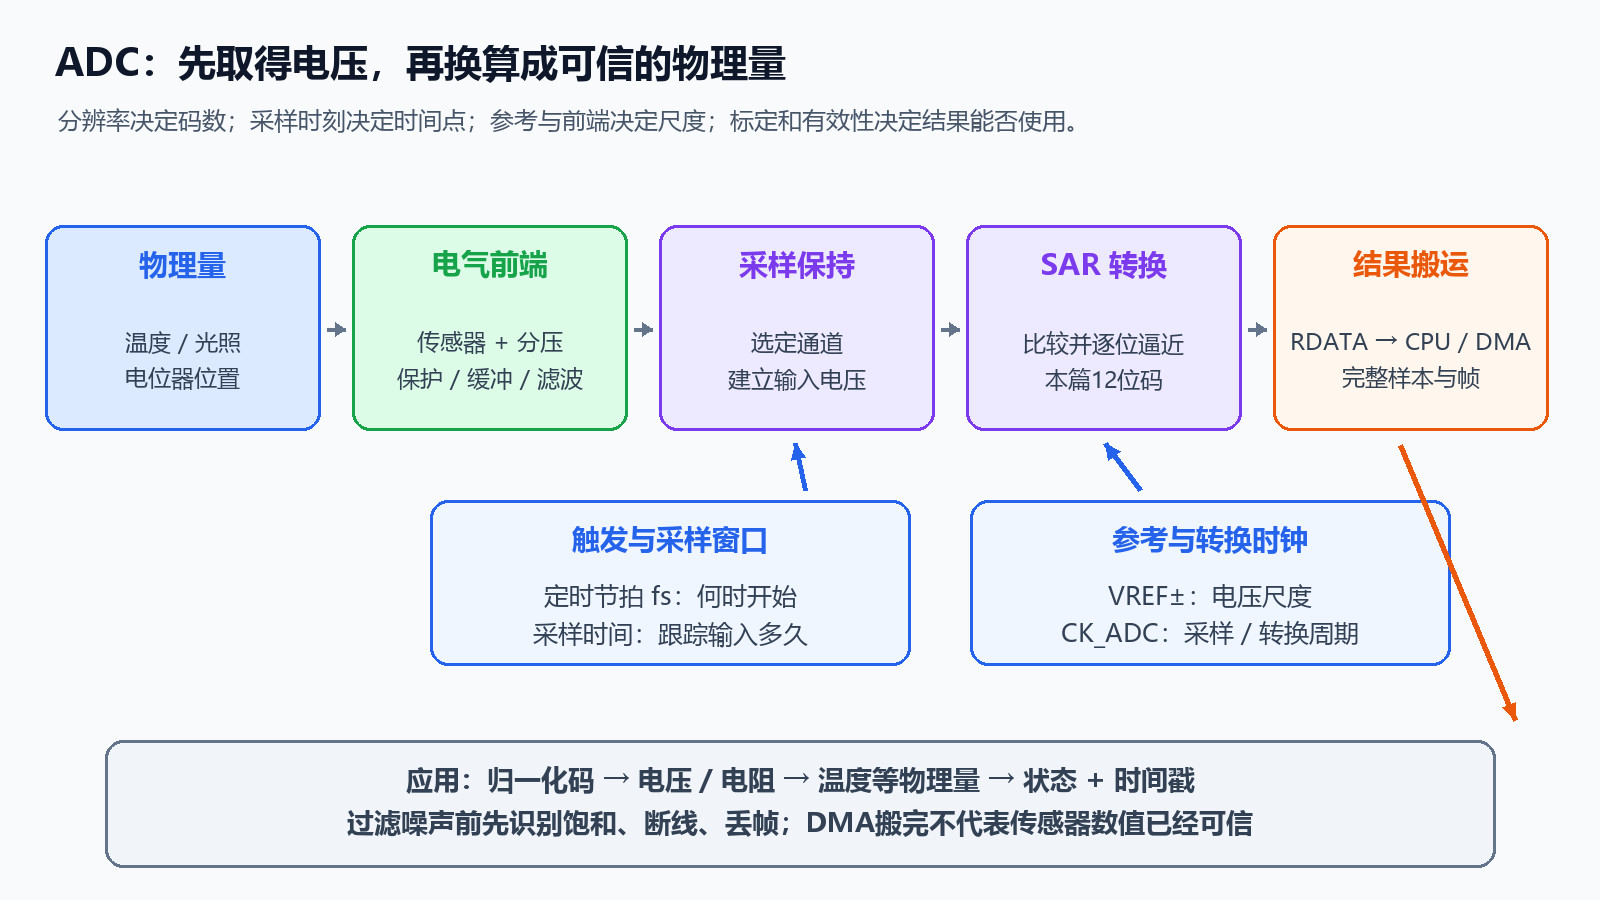

示意图中的采样保持不是“CPU 读到寄存器的那个瞬间”。硬件先在采样阶段让内部电容跟踪输入，然后保持电压完成转换，最后写结果寄存器。串口打印发生得更晚。

| 参数 | 决定什么 | 常见误解 |
|---|---|---|
| 采样频率 fs | 每秒取得多少个新样本 | 不等于 ADC 时钟 |
| 分辨率 N | 可表示多少个量化码 | 不等于整套系统准确度 |
| 参考电压 Vref | 数字码对应的电压尺度 | 不一定恰好是标称 3.3 V |
| 采样时间 | 内部采样电容跟踪输入多久 | 不是应用每隔多久采一次 |
| 转换时间 | SAR 完成判断所需时间 | 不包括所有软件与搬运延迟 |

ADC 模块常用 SAR，即逐次逼近：先试高位，通过比较器判断，再逐位逼近结果。Flash ADC 使用多比较器并行判断，速度可高，但比较器数量随位数增长。这里的“Flash ADC”不是用于保存程序的 Flash 存储器。

理解参数后，先针对信号带宽与源阻抗确定采样需求，再配置硬件，不从“所有设置取最快”开始。


## 4. 分辨率：4096 个码，最大码是 4095

N 位无符号码的数量为 `2^N`，范围为 `0～2^N−1`。

| 分辨率 | 码数量 | 归一化整数范围 | 3.3 V 满量程的理想 LSB |
|---|---:|---:|---:|
| 6 bit | 64 | 0～63 | 51.5625 mV |
| 8 bit | 256 | 0～255 | 12.890625 mV |
| 10 bit | 1024 | 0～1023 | 3.222656 mV |
| 12 bit | 4096 | 0～4095 | 0.805664 mV |

理想量化间隔为：

```text
LSB = (VREF+ − VREF−) / 2^N
```

12 位、参考跨度 3.3 V，LSB 约 0.806 mV。课程热敏电阻页写“范围0～4096”，应改为 **0～4095**；4096 是等级数量，不是合法最大原始码。

当输入落在同一个量化区间，小幅变化可能得到相同码。结果达到 4095，只说明进入最高码区间或饱和，不能证明电压精确等于 3.300000 V。

理想模型用区间代表值重建时，量化误差常描述为约 ±0.5 LSB；实际还包含偏移、增益、非线性、噪声和参考误差。不同 ADC 的转换阈值、端点定义要看数据手册，不能把理想模型当作实物校准曲线。

“把 12 位平均成浮点数后保留 6 位小数”只改变表达格式，不会自动增加传感器准确度。读数的有效位数应结合误差与标定决定。


## 5. 4095 与 4096：区分端点映射和量化尺度

课程 ADC 开发页强调除以4095，NTC 页则采用4096。两者代表不同的估算约定，不能用“4095能算到3.3V”证明它永远正确，也不能忽略量化模型。

| 用途 / 约定 | 公式，12位且VREF−=0 | 含义 |
|---|---|---|
| 两端点线性映射 | `V_est = code × Vref / 4095` | 将0码映射到0，将4095码映射到Vref |
| 理想量化尺度 | `V_est = code × Vref / 4096` | 每个码按一个LSB推进，常作简化估算 |
| 区间中点重建示例 | `(code+0.5) × Vref / 4096` | 仅适用于所选理想区间模型，不是通用器件定义 |
| 实测标定 | `V_est = a×code+b`或更完整模型 | 使用已知输入/参考修正系统误差 |

例：`code=2048，Vref=3300 mV`：端点映射为 **1650.403 mV**；按4096尺度为 **1650.000 mV**。差约0.403 mV，小于此模型的一个LSB，但系统里所有函数应采用一致约定。

本篇应用换算示例使用 **12位右对齐、未过采样、端点映射**，与课程多数应用展示保持一致；理论 LSB 使用4096。若需要精密测量，使用器件实际传递函数、参考实测与标定，不把映射端点当精度保证。

下面为独立 C99 整数毫伏换算，限定合法12位码和本示例允许的参考值。先扩大乘法，最后四舍五入。

```c
#include <stdint.h>
#include <stdbool.h>
#include <stddef.h>

static bool adc12_to_mv(uint16_t code, uint32_t ref_mv, uint32_t *out)
{
    if (out == NULL || code > 4095u || ref_mv < 2400u || ref_mv > 3600u)
        return false;
    uint64_t numerator = (uint64_t)code * ref_mv;
    *out = (uint32_t)((numerator + 2047u) / 4095u);
    return true;
}
```

此处假设 VREF− 为0；参考范围检查服务于本篇平台，未替代电气规格。先做 `code/4095` 的整数除法会让大多数结果为0；`code*ref_mv` 的类型也必须足够宽，不能乘完溢出后再转成64位。


## 6. 参考、电源与输入范围：先保证电压合法

ADC 判断的是输入相对参考的位置。`VDDA` 是模拟供电，`VSSA` 是模拟地；`VREF+/-` 决定尺度，具体封装可能将参考与模拟供电连接，需看引脚与原理图。

官方手册给出正常转换输入区间 `VREF− ≤ VIN ≤ VREF+`，模拟供电2.6～3.6 V，并要求VDDA/VSSA与VDD/VSS按规定连接。参考VREF+还需满足数据手册约束。**正常转换区间和绝对最大额定值是不同概念**，超过正常区间的码不能作为可靠测量。

| 条件 | 影响 |
|---|---|
| 参考实际为3.25 V，换算仍写3.30 V | 约产生1.538%的尺度偏差 |
| 模拟地被大电流抬高 | 输入相对参考变化，读数随负载跳动 |
| VDDA去耦或电源纹波不佳 | 参考/内部转换受干扰 |
| 传感器输出超过参考或低于地 | 结果饱和、测量无效，可能超电气限制 |
| 数字口具备某种5V容忍 | 不能据此推断模拟模式可以采5V |

例如实物输入1.650 V、参考3.25 V，理想比例对应约2079码；若用3.30 V换算，会显示约1.675 V。只增加平均次数无法消除这个参考尺度错误。

测量更高电压要先分压、缓冲或转换，并考虑最大输入、误差、上电顺序、保护、电阻功率与 ADC 源阻抗。不要把5V/电池直接接到3.3V模拟输入来试“是否能读满量程”。

电位器、NTC若由与ADC参考相同的电源激励，可采用比例测量，部分供电变化会在比值中抵消；抵消依赖同源、同时、实际布线与稳定性，不能覆盖所有电路误差。


## 7. 采样频率与混叠：滤波必须发生在合适的位置

采样周期 `Ts=1/fs`。温度每秒采几次通常足够，但振动、电流波形等需要按信号频带设计。

带限信号要避免混叠，理论上采样频率需大于最高频率的两倍；实际还需留抗混叠滤波的过渡带和时序裕量。不是只满足“恰好两倍”就能恢复所有波形。

例：`fs=1000 Hz`，某900 Hz干扰采样后可能表现为100 Hz变化，因为900 Hz与100 Hz在采样点上发生频率折叠。**采样后做数字平均不能判断低频100Hz来自真实信号还是已混叠的900Hz**。需要在ADC前控制输入带宽。

| 措施 | 位置 | 主要作用 |
|---|---|---|
| 模拟RC / 有源低通 | ADC前 | 限制带外信号进入采样过程 |
| 定时硬件触发 | 采样时刻 | 减少软件调度造成的时间抖动 |
| 数字均值 / IIR | 采样后 | 平滑已采得的数据，但引入延迟 |
| 降采样前数字低通 | 高速样本到低速输出之间 | 减少再次降采样造成的混叠 |

一阶RC的截止频率 `fc=1/(2πRC)`。10 kΩ与100 nF的简单RC模型约159.15 Hz。实际分压节点的等效电阻可能是并联值，不一定就是上拉10 kΩ；第20节会按NTC电路计算。

打印频率也不是采样频率。每秒打印一次，可能打印的是一秒前某时刻的值、32个值的平均，或连续转换中的最新值；应在数据结构中明确时间与统计窗口。


## 8. 采样时间：给内部电容足够的建立时间

SAR ADC 输入近似包括通道开关和采样电容。输入源要在采样窗口内给电容充电，源阻抗越高、阶跃越大，建立越慢。

学习用简化模型：

```text
采样残差比例 ≈ exp(−t_sample / τ)
τ ≈ (R_source + R_switch) × C_sample
若12位满幅阶跃要求残差 < 0.5 LSB：
t_sample > ln(8192) × τ ≈ 9.011 × τ
```

假设总等效电阻10 kΩ、采样电容10 pF，τ=100 ns，约需0.901 μs；这是**说明原理的假设参数，不是GD32F407实测/数据手册数值**。实际要按器件输入参数、允许源阻抗、放大器建立和电路设计选择。

官方ADC采样时间档位为 **3、15、28、56、84、112、144、480 个 CK_ADC 周期**，每个通道可分别配置。ADC时钟21MHz时，3周期只有0.143μs，144周期约6.857μs。

| 情况 | 可考虑的处理 |
|---|---|
| 电位器/高阻分压 | 增加采样时间，核对等效源阻抗 |
| 通道间电压差大 | 延长采样、调整顺序，按需求重复采样并验证 |
| ADC前有滤波电容 | 评估动态响应与采样冲击，不能只看静态电压 |
| 内部温度/VREFINT | 启用内部路径，满足专用启动和最小采样时间 |
| 高速信号 | 低源阻抗与合适缓冲，兼顾带宽和转换周期 |

第一次采样与后续不同，不一定是随机噪声，也可能是通道切换留下的电荷。丢弃第一样本有时有效，但应通过器件要求和重复测试确定，不能掩盖根本不够的采样时间。


## 9. ADC时钟、转换时间、应用采样率分别计算

ADC时钟推动采样与SAR转换；应用触发决定何时开始。官方手册第284页对12位转换给出：

```text
t_one = (采样周期数 + 12) / fADC
```

这里是12个转换周期，**不要照搬其他系列的12.5周期**。降低分辨率时转换周期相应改变；过采样和多通道序列还会增加总工作量。

例：`PCLK2=84 MHz，ADC选择PCLK2/4`，`fADC=21 MHz`：

| 每通道采样档位 | 12位总周期 | 理想单次时间 |
|---:|---:|---:|
| 3 | 15 | 0.714286 μs |
| 28 | 40 | 1.904762 μs |
| 144 | 156 | 7.428571 μs |
| 480 | 492 | 23.428571 μs |

三个通道都用144周期，一轮约 **22.285714 μs**，尚未计特定硬件开销。每毫秒触发一轮时，一轮内三个通道的采样时刻依次错开；每个通道1000样本/秒，总结果数3000项/秒。

手册ADC时钟上限为40MHz，实际工作条件与型号数据手册仍需核对。例中84MHz除2得到42MHz，已经超过该上限；不能因为更快就选除2。常用PCLK2除2/4/6/8，另有HCLK分频路径，见第13节。

连续转换时，速率接近硬件周期决定的吞吐量；定时触发单次序列时，速率主要由触发周期决定。定时周期必须大于整轮转换/过采样需要的时间，并留出裕量；ADC还忙时来的触发不能假定都排队保存。


## 10. 分辨率和对齐：寄存器值不一定是归一化码

12位右对齐最易理解：有效码在低12位，读值0～4095；左对齐时有效码移到16位数据区域的高12位，需右移4位恢复。

GD32F4xx User Manual 3.4 第283、286页还有一个容易漏的特点：**10/8位转换在右对齐布局中仍放入12位尺度，未使用低位为0**。

| 选择的分辨率 | 右对齐数据区布局 | 恢复N位归一化整数 |
|---|---|---|
| 12 | `D11…D0`位于bit11…0 | `data & 0x0FFF` |
| 10 | `D9…D0`位于bit11…2 | `(data & 0x0FFF) >> 2` |
| 8 | `D7…D0`位于bit11…4 | `(data & 0x0FFF) >> 4` |
| 6 | 图示`D5…D0`位于bit11…6，特殊布局 | `(data & 0x0FFF) >> 6`，按具体手册核对 |

因此10位转换读取结果不一定直接是0～1023：其右对齐12位区域最大可为4092。若直接按1023除，会算出约四倍电压。图14-10的标题误写8位，正文实际讲6位，本篇按位图解释。

对12/10/8位左对齐，归一化值分别从数据区右移4/6/8位。6位在手册中单独给布局，不套用未定义的普通左对齐假设。修改分辨率需先关闭ADC；不要在转换进行中修改。

过采样输出可能占用完整16位，不能继续一律 `&0x0FFF`。**归一化函数必须知道分辨率、对齐和过采样缩放**，否则一个掩码就可能丢掉合法高位。

本篇后续 `raw12` 均表示已正确解码的12位右对齐、未过采样码；不用这个名称指代任意寄存器原值。


## 11. 引脚、通道、序列位置：三个编号

ADC引脚是电路接线，通道号选择内部多路开关，序列位置决定转换顺序。

| 本篇采集对象 | 引脚/内部路径 | ADC0通道 | 示例序列位置 |
|---|---|---:|---:|
| 电位器滑动端 | PA0 | IN0 | rank0 |
| NTC分压点 | PA1 | IN1 | rank1 |
| 芯片内部温度 | 无外部输入脚 | IN16 | rank2 |
| 内部参考 | 无外部输入脚 | IN17 | 按需要单独或加入序列 |
| VBAT/4 | 内部电池分压 | IN18 | 按需要单独或加入序列 |

`rank1` 不等于通道1：完全可以把IN16放在rank1。DMA结果通常按**序列位置**排列，应保存对应表，而不是用物理通道号直接作紧凑数组下标。

课程查询页提供不同ADC实例的外部引脚表，例如ADC2的部分通道改用PF引脚。实际封装可能没有某脚，不能复制全系列引脚表后就认为本板都可用。

外部模拟脚配置为模拟模式、无上下拉，避免数字输入路径与内部电阻影响信号。通常不需要给ADC输入设置像I2C/SPI那样的数字AF号。

```c
/* GD32F4xx SPL的GPIO片段；ADC初始化在后续步骤完成。 */
rcu_periph_clock_enable(RCU_GPIOA);
gpio_mode_set(GPIOA, GPIO_MODE_ANALOG, GPIO_PUPD_NONE,
              GPIO_PIN_0 | GPIO_PIN_1);
```

先核对PA0/PA1是否被按键、串口、触摸或其他电路占用。测量同一脚的数字电平和模拟电压不是同时随意切模式的无影响操作。


## 12. 单次、连续、扫描：组合的是两个维度

“是否扫描多个通道”与“完成一轮后是否自动继续”是两件事，不能把四种组合当相互排斥的四个硬件模块。

| 模式 | 一次触发后的行为 | 适合场景 |
|---|---|---|
| 单次 + 非扫描 | 转换选定单通道一次后停 | 电位器/慢速传感器的定时读值 |
| 连续 + 非扫描 | 同一通道反复转换 | 单信号连续监测 |
| 单次 + 扫描 | 按序转换一轮后停 | 定时采集多通道帧 |
| 连续 + 扫描 | 按序反复转换多通道 | 固定硬件吞吐的多路流，通常配DMA |

扫描是在同一个ADC内部按顺序选择通道，**不是多个通道在同一瞬间同时采样**。对变化很快的信号，通道间延迟会影响相位和比较；需要真正同步时，另行评估多个ADC的同步模式和限制。

本篇多数系统示例采用 **定时器触发 + 扫描 + 连续关闭 + DMA**：每次硬件触发得到一帧，便于定义采样周期。若同时开启连续模式，第一次触发后就可能自由运行，后续节拍不再等于期望的1kHz。

不连续模式会把一轮拆成若干次触发完成，每次转换数量另有配置，不是“连续模式关闭”的别名。本篇不展开多ADC并行/跟随、同步DMA等高级组合。

课程框图中的“规则/常规”和“插入/注入”名称跨版本可能不同；不要只凭一张通用结构图创建手册未定义的函数。先把匹配本机常规采集跑通，再根据本机资料扩展。


## 13. 初始化与校准：先稳定，再启动新转换

初始化建议按下面顺序组织，所有等待要有界：

```text
确认采样电路、参考和GPIO合法
→ 使能GPIO/ADC时钟，停掉旧触发和DMA，建立可重入的初始状态
→ 配置ADC公共时钟与独立模式
→ ADC关闭时配置分辨率、对齐、模式、序列、采样时间和触发
→ 若采内部通道，开启对应内部路径并等待规定建立时间
→ 使能ADC，满足数据手册tSU与校准前稳定要求
→ 可选复位校准寄存器，启动校准，有界等待完成
→ 清旧完成/错误状态，准备结果搬运
→ 最后允许触发，开始采集
```

可见课程片段使用：

```c
/* GD32 SPL片段：若PCLK2=84MHz，则fADC=21MHz。 */
rcu_periph_clock_enable(RCU_ADC0);
adc_clock_config(ADC_ADCCK_PCLK2_DIV4);
```

ADC时钟字段在ADC0公共控制区域，对ADC1/2配置公共分频时也要使能ADC0时钟。手册给出的公共选择包括PCLK2/2、/4、/6、/8，以及HCLK/5、/6、/10、/20；不要把CPU频率直接当ADC频率。

校准前必须ADC已使能，手册要求延迟至少14个CK_ADC等待稳定，且使能采样前还有芯片数据手册规定的 `tSU`。两项要求都要满足，不能把“14周期”当所有器件启动延时的全部条件。

校准期间不采样，CLB由硬件在完成后清除。手册自校准约131个ADC周期，是硬件特性说明；驱动等待仍应有期限和失败返回。某些SPL校准函数内部可能无限轮询，调用前应检查实现并按工程要求补充有界路径。

内部校准修正ADC内部特性，不能替代传感器参数、分压电阻、参考电压和整机温度标定。手册建议工作条件明显改变后重新校准；恢复/重建采集时也应重新明确参考、时钟与校准状态。


## 14. 单通道轮询：只交付一次新的完整采样

最小基线可以是电位器PA0/ADC0_IN0，12位右对齐，单次非扫描，软件触发。不要一开始就混入DMA、滤波和多个传感器。

```text
获取采集实例所有权
→ 确认没有旧转换在途，选择通道与采样时间
→ 清旧EOC/检查错误，设定单次预算
→ 软件触发
→ 等待新EOC，同时检查ROVF和超时
→ 读取一次结果，校验格式与范围
→ 发布新样本与时间，释放所有权
```

以下为应用接口流程，`board_adc_*`需要实际驱动实现；它不是可直接链接的SPL工程。假设已配置12位右对齐非扫描、无DMA，`limit`是第08篇的活动期间单调时间预算。

```c
static app_status_t app_adc_read_once(uint16_t *out,
                                      const app_limit_t *limit)
{
    if (out == NULL || limit == NULL) return APP_BAD_ARG;
    if (!board_adc_ready_idle()) return APP_BUSY;
    board_adc_clear_old_completion();
    board_adc_start_once();
    for (;;) {
        if (board_adc_overrun()) return APP_IO_ERROR;
        if (app_limit_expired(limit, board_mono_us())) return APP_TIMEOUT;
        if (board_adc_eoc()) break;
    }
    uint32_t data = board_adc_read_data();
    if (data > 4095u) return APP_FORMAT_ERROR;
    *out = (uint16_t)data;
    return APP_OK;
}
```

前置条件包含正确格式；如果读到异常高位，应排查对齐/过采样而不是直接掩码隐藏问题。状态枚举和计时接口由工程定义；本函数错误返回后，所有者仍需按硬件策略结束在途转换并恢复基线，再允许重试。

**读DATA和清EOC的顺序要看本机。** 官方第293页说明EOC可写0清，也可读ADC_RDATA清；不要以为每次读都是无副作用。调试器自动查看RDATA可能改变状态，日志也不要重复读取后丢失唯一结果。

返回超时不能把上次成功值冒充本次值。接口失败时不更新调用者输出，新旧样本用有效状态与时间戳区分。


## 15. 内部温度、VREFINT与VBAT：各有专用含义

| ADC0通道 | 功能 | 关键约束 |
|---|---|---|
| IN16 | 芯片内部温度传感器 | 内部路径使能、稳定/采样时间、芯片个体偏移 |
| IN17 | VREFINT内部参考 | 启用路径，使用真实规格/校准值，不能直接假定所有芯片一样 |
| IN18 | VBAT内部监测 | 内部分压后读到VBAT/4，启用分压会增加电池负载 |

IN16/17由ADC公共区域TSVREN使能，IN18由VBATEN使能。手册寄存器定义指出这些内部有效路径在 **ADC0**；ADC1/2相应通道连接VSSA，不能把ADC0的内部温度配置简单换个实例。

内部温度主要反映**芯片自身温度**，受功耗、封装、板子散热影响，不能直接当房间空气温度。官方手册也提示个体偏移可能很大，更适合看变化，精密绝对温度需外部校准。

手册温度模型为：

```text
T(°C) = (V25 − Vsense) / Avg_Slope + 25
```

V25与Avg_Slope应取具体芯片数据手册/校准参数，并保持单位一致。例如只为说明运算，假设V25=760mV、Avg_Slope=2.5mV/°C、读到Vsense=735mV，则模型为35°C；**这些假设值不是本篇确认的GD32F407标定常数**。

VREFINT可用于估算实际参考尺度，但需要其实际参考值或厂商校准数据。例如按本篇端点映射约定：`Vref_est≈Vrefint_known×4095/code_vrefint`；码为0、路径未稳定、参考值只是未经校准的典型数时不能交付高精度结论。

VBAT读数经内部除4，恢复电池电压时乘4。先检查通道使能、时序与适用输入范围，用完按需求关闭分压路径降低不必要负载。不能把内部VBAT路径当外部GPIO允许输入同样高电压的证据。


## 16. 多通道扫描与EOC：最后一个寄存器装不下整帧

常规序列最多16项，虽然可选择的通道总数可更多。硬件长度字段RL存“长度减1”；库函数参数若接收实际长度，就不要自己再减一次。

示例序列：`rank0=IN0电位器，rank1=IN1 NTC，rank2=IN16内部温度`。一个触发产生三次依次转换，结果先后写入同一个ADC_RDATA。

```text
触发 → IN0结果写RDATA → IN1结果写RDATA → IN16结果写RDATA → 一轮结束
```

因此等一轮结束后读RDATA三次，不能得到三个历史结果；可能只读到相同的最后值。官方第281页的扫描流程要求配置DMA，将每个通道结果在被覆盖前搬到内存。

EOC由 `EOCM` 决定：

| EOCM | EOC何时置位 | 数据溢出检测 |
|---:|---|---|
| 0 | 整个常规序列结束 | DMA开启时仍检测；否则按手册条件 |
| 1 | 每个常规通道转换结束 | 自动检测 |

DMA请求在每个常规通道完成时产生，与EOC是否只在序列末尾置位不同。不能用“EOC只来一次”推断DMA只搬一次。

应用可选择每轮手动切通道并单次读取，作为低速独立采集；它与硬件扫描不是同一配置，也没有保证三路同时采样。明确选定一种方式，避免混合两种结果顺序。

真正多个ADC同步模式有公共触发、独立/并行/跟随等限制；同一个模拟通道也不应让两个ADC采样窗口重叠而不核对手册。本篇核心先使用单ADC扫描与DMA。


## 17. 定时器触发：把采样节拍交给硬件

主循环中的 `delay_ms(1); start_adc();` 会叠加处理、打印和调度耗时，难以形成精确1ms采样周期。需要均匀节拍时，用定时器比较事件/TRGO等允许源触发ADC。

示例目标：每1ms采一帧三通道，12位、单次扫描、每通道144周期，ADC21MHz，一轮理想22.286μs，显著小于1ms周期。每路1000SPS，总3000转换/秒。

```text
TIMER周期/比较事件 → ADC选择该触发源与有效边沿
→ 顺序采一轮 → DMA按序搬结果 → 等下一次TIMER事件
```

官方第284页列出如TIMER1_TRGO、TIMER2_TRGO、TIMER7_TRGO及若干CH事件、EXTI11。**不是所有TIMER更新事件都能直接触发ADC**；要核对触发源编号、TRGO输出配置和边沿使能。

定时器频率按第05篇核对TIMER实际时钟及APB分频规则；ADC时钟则按它自己的公共分频计算。两类时钟公式不能混用。

硬件启动顺序很关键：先配置GPIO/ADC/校准与DMA，清状态并使接收通道可用，最后启动定时器触发。初始化TIMER产生的软件更新事件可能顺带产生TRGO，不要在DMA未准备时让它启动一轮。

输出时间戳最好定义为这一帧的触发时刻，再给各rank加上可解释的采样偏移；DMA中断到达时刻只是“搬完时刻”。对慢温度显示差别小，对电流相位和多通道相关分析则有意义。


## 18. ADC + DMA：循环缓冲、帧布局与所有权

DMA方向为外设到内存，源为ADC_RDATA且地址固定，目标数组递增。映射必须核对实际DMA控制器/通道/subperipheral，不能照搬第06篇USART的映射。

ADC_RDATA有效数据区为16位，手册规定CPU寄存器按32位访问。DMA位宽须按实际手册/SDK确认；本篇用 **32位存储的布局示例**便于说明，每项低位保存已解码的结果，未声称所有工程只能用这一位宽。

```c
#define CHANNELS         3u
#define FRAMES_PER_HALF 32u
#define HALF_ITEMS      (CHANNELS * FRAMES_PER_HALF)
#define TOTAL_ITEMS     (2u * HALF_ITEMS)

/* 示例搬运布局，实际对齐/可访问内存与DMA配置要匹配。 */
static uint32_t adc_dma[TOTAL_ITEMS];
```

总计192项、768字节。每帧排列为`pot,ntc,temp`：第k帧第r路位于 `k*CHANNELS+r`，不是 `r*帧数+k`。DMA计数192表示项数，不是字节数；若实际使用16位，则数组和计数/宽度同时重新设计。

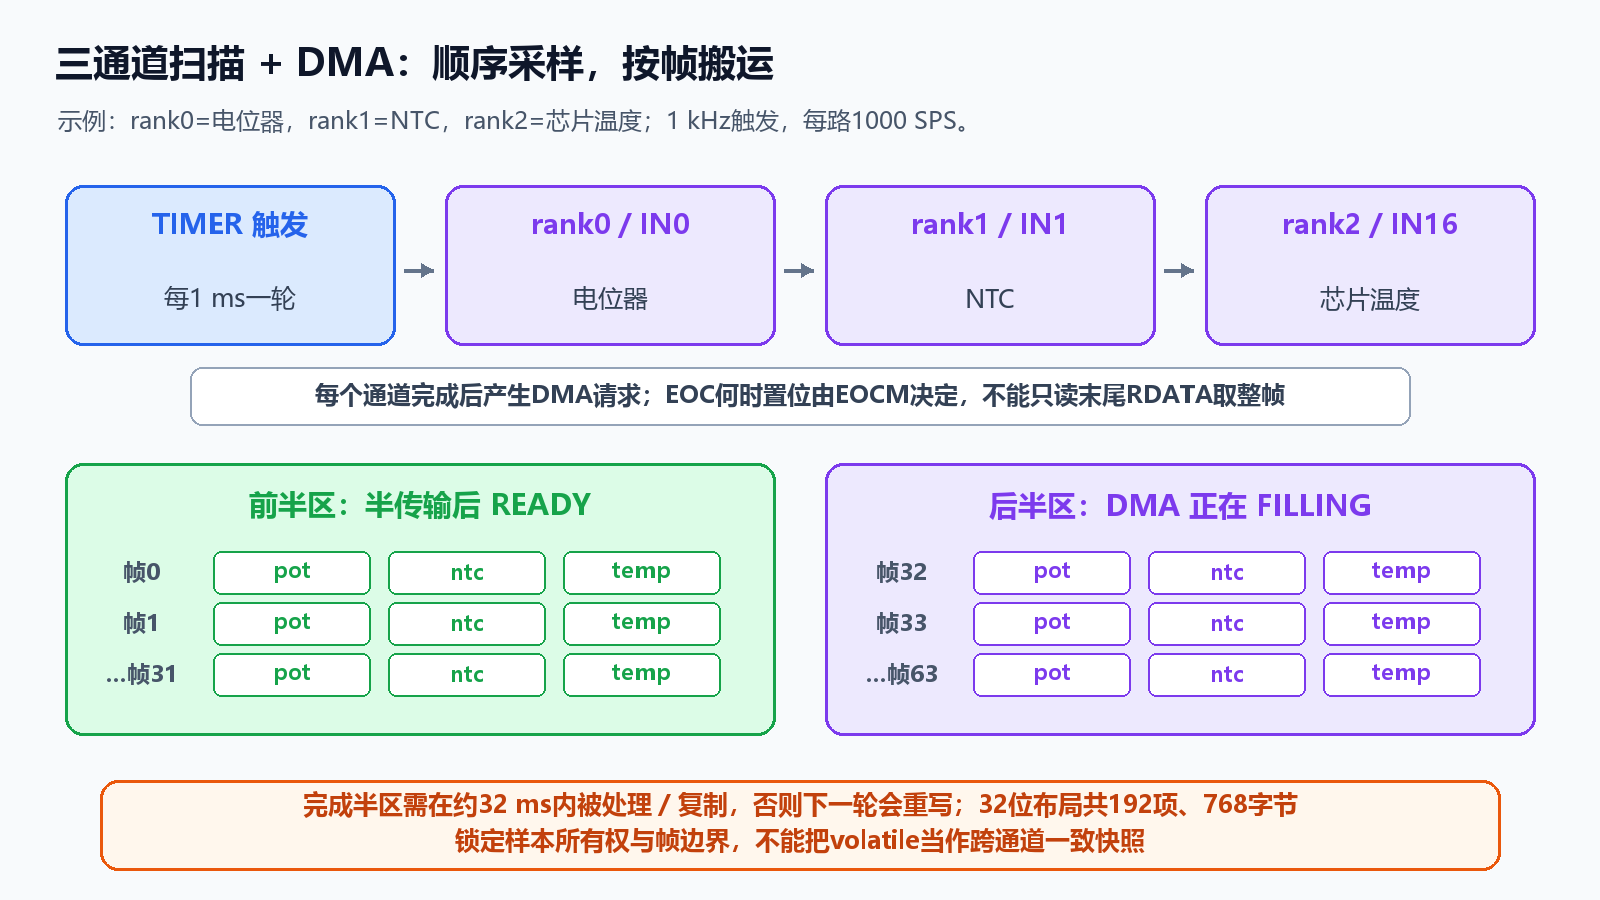

配置要同时考虑ADC DMA请求持续模式与DMA循环模式。手册的DDM决定完成一次搬运后ADC DMA引擎是否继续请求；只开启DMA循环，不保证ADC端继续产生后续请求。

半传输完成时前半区已填满，DMA写后半区；全传输完成时后半区已填满，DMA回到前半区。**全完成不代表循环采集停止**，也不代表整个数组在很长时间内保持稳定。

每1ms一帧，每半区32帧，完成一半后应用大约有 **32ms** 在它再次被写前处理。窗口不是额外存储，只是当下的时间裕量；ISR通知延迟和调度耗时会缩短可用时间。

可用短ISR记录完成半区、递增序号并通知任务；任务在截止前复制/处理已完成区，或用硬件支持的双缓冲与明确的FREE/FILLING/READY/PROCESSING所有权。若处理超过期限，则判丢帧/覆盖，不能混用两轮数据。

`volatile`不会使3个通道同时更新，也不会阻止DMA重写。通知序号/索引要用工程合适的原子操作或短临界区同步，必要时内存屏障/缓存维护按具体芯片要求处理；不能只给数组加volatile就声明一致快照。


## 19. 溢出与恢复：一帧不完整就不交付

ADC `ROVF` 表示上一个常规数据尚未读走，下一个转换已完成，最近结果丢失。手册说明在DMA开启或EOCM=1时有相应溢出检测，出现后转换会暂停，不能只清一个标志后假定所有数据仍对齐。

| 故障 | 需要检查 |
|---|---|
| DMA不动 | 请求映射、外设地址、ADC DMA使能、触发、通道启用 |
| 只搬一轮 | ADC端DDM/请求持续、DMA循环、连续/触发配置 |
| ROVF | DMA带宽/配置、目标内存、调试读取、触发率与通道阻塞 |
| 半区内容跨帧 | 长度未按通道数整除、消费晚、重启rank未对齐 |
| DMA错误 | 位宽、对齐、地址合法、不可访问内存、映射冲突 |

恢复先阻止新触发，记录错误与序号，作废当前未确认完整的块。官方第285页建议关闭ADC DMA请求与ADC，禁用并重初始化DMA，按规定写0清ROVF，然后重新启DMA、ADC请求与ADC，等待稳定，再允许触发。

实际驱动把这些步骤作为有界状态机；确认DMA通道已停后才能修改配置或归还目标内存。重启后从新帧边界计数，校准策略、启动时间及内部通道条件也要重新核对。

不正常数据不应通过“拿上一帧补上”伪装成真实新样本。可返回丢帧标志、重启标志和新序号，让控制/日志知道时间序列断开。

调试断点可能停止CPU而外设继续运行，造成DMA覆盖或ADC溢出。遇到“单步失败、全速成功”，先看调试保持策略和波形，不立刻把它当算法错误。

错误处理要清楚哪些资源共用：公共ADC分频、DMA通道和触发定时器若被其他业务使用，不能在一个传感器失败时不加协调地整体复位。


## 20. 电位器与NTC分压：按实际接线推导

电位器可把两端分别接到兼容的激励电源与地，滑动端接PA0。理想情况下转动对应0～参考范围的比例；端点是否真的到达电源轨、滑动端接触噪声和负载影响，要实测。

可先用端点映射将电位器变成0～1000的比例：

```c
/* 前提raw12已验证为0～4095；这是无单位比例，不是温度。 */
uint32_t permille = ((uint32_t)raw12 * 1000u + 2047u) / 4095u;
```

课程NTC原理图经视觉核对：**上方固定10kΩ电阻连接VCC，下方NTC接地，PA1接中点，100nF电容从中点接地**。本篇沿用这个方向。

```text
Vexc ── Rpull=10kΩ ──●── Rntc ── GND
                      |
                      +── PA1 / ADC0_IN1
                      |
                    C=100nF
                      |
                     GND
```

分压公式：

```text
Vnode = Vexc × Rntc / (Rpull + Rntc)
Rntc = Rpull × Vnode / (Vexc − Vnode)
```

若激励Vexc与ADC参考同源、VREF−=0，并采用本篇端点映射，可消去电压：

```text
Rntc = Rpull × raw12 / (4095 − raw12)
```

升温时NTC阻值下降，这种接法的节点电压/ADC码也下降。若把NTC移到上方、固定电阻放下方，公式和趋势相反：`Rntc=Rfixed×(Vexc/Vnode−1)`。**公式先从电路推导，不能根据“也是NTC”直接复制。**

10kΩ固定电阻与10kΩ NTC相等时，中点约一半电源，理想比例码在2047/2048附近；用2048代入端点模型，Rntc≈10004.885Ω。NTC短路时节点接近0；NTC开路时节点接近Vexc。端点也可能来自超量程、错误接线或极端温度，要结合允许温区设置诊断窗口。

分压源等效电阻是 `Rpull || Rntc`。两者10kΩ时为5kΩ，与100nF构成约0.5ms时间常数，简化小信号截止频率约 **318.31Hz**。这既影响抗干扰，也影响通电后/激励切换后的等待时间。

NTC会自热：3.3V、两只10kΩ串联时电流165μA，NTC功耗约 **0.27225mW**。温升需除以器件耗散系数才能估算，不能凭功耗小就声称绝对没有温升。降低/间歇激励也必须等待节点和ADC充分稳定。


## 21. NTC阻值换算与B模型：先判故障，再取对数

NTC阻温曲线是非线性的。得到阻值后，可按厂商表、B参数或Steinhart-Hart参数换成温度。

常见B模型：

```text
R(T) = R0 × exp[B × (1/T − 1/T0)]
T(K) = 1 / [1/T0 + ln(R/R0)/B]
T(°C) = T(K) − 273.15
```

T、T0必须用开尔文，`ln`是自然对数。R0是标称温度T0处的阻值；B也有指定温度区间，不能把任何“10k NTC”都假定B=3950。

以下为独立C99算法，示例参数为**假设10kΩ@25°C、B=3950K的NTC、10kΩ上拉**，用于说明运算，未核对为课程实物B参数。

```c
#include <math.h>
#include <stdint.h>
#include <stdbool.h>
#include <stddef.h>

static bool ntc_beta_from_adc12(uint16_t raw12,
                                 double r_pull, double r0,
                                 double b_kelvin, double t0_kelvin,
                                 double *out_c)
{
    if (out_c == NULL || raw12 == 0u || raw12 >= 4095u)
        return false;
    if (!isfinite(r_pull) || !isfinite(r0) || !isfinite(b_kelvin) ||
        !isfinite(t0_kelvin) || r_pull <= 0.0 || r0 <= 0.0 ||
        b_kelvin <= 0.0 || t0_kelvin <= 0.0)
        return false;

    double r_ntc = r_pull * (double)raw12 / (4095.0 - raw12);
    if (!isfinite(r_ntc) || r_ntc <= 0.0) return false;
    double inverse_t = 1.0 / t0_kelvin + log(r_ntc / r0) / b_kelvin;
    if (!isfinite(inverse_t) || inverse_t <= 0.0) return false;
    double celsius = 1.0 / inverse_t - 273.15;
    if (!isfinite(celsius)) return false;
    *out_c = celsius;
    return true;
}
```

调用示例：`ntc_beta_from_adc12(raw12,10000.0,10000.0,3950.0,298.15,&t)`。工程还需检查采集是否有效、温度是否在实际型号适用区间、是否接近轨、参数版本和ADC参考条件。

这里拒绝0/4095避免除零和对数无效，**不等于中间所有码都表示健康探头**。可按器件允许温区建立更保守的码窗口，并用持续时间确认断线；异常保持独立状态，不把失败返回的旧变量当作新温度。

近两端时码的小变化会造成阻值很大比例变化，误差与灵敏度随温度而变。固定电阻精度、NTC容差、B误差、自热、安装位置和参考稳定性均会影响结果，不能用浮点计算“看起来很精细”替代这些误差评估。


## 22. NTC查表与插值：下标不天然等于温度

课程建议按阻温表查温度。这通常比未经校准的单一B模型更贴近具体器件曲线，但必须保留表的型号、单位、温度范围和采样间隔。

假设下列学习表按温度升序、阻值降序排列，数值来自第21节假设B模型的近似值，**不是课程附件的原始阻温表**：

| 温度 | 阻值，约Ω |
|---:|---:|
| 0°C | 33620.6 |
| 25°C | 10000.0 |
| 50°C | 3588.2 |

查到相邻点 `(R1,T1)`、`(R2,T2)`，线性插值示意：

```text
T ≈ T1 + (R − R1) × (T2 − T1) / (R2 − R1)
```

上述25°C间隔太宽，NTC非线性使插值误差较大；它只说明算法。实际使用厂商更密表，或对适合的变量插值并验证误差。不能拿三点稀疏表就承诺精确温度。

推荐表项明确存 `r_ohm` 和 `t_c`，不要只存阻值然后默认数组下标是摄氏温度。若表从−40°C开始、每0.5°C一项，下标k对应 `−40+0.5k`，还应考虑固定点表示。

查表算法约定：

1. 检查表长至少2、阻值严格单调、温度一致排序，禁止重复阻值分母为0。
2. 输入落在表范围之外，返回超范围；若显示层选择钳位，必须另带超范围标志。
3. 在范围内找到一对夹住R的相邻项；边界相等时直接返回表值。
4. 用足够宽的运算插值，检查单位与数值有效性，再返回温度。

大型表可二分查找，但阻值降序要反转比较方向。温度传感器几秒采一次时，几十/几百项线性查找也可能足够；先确保正确和可验收，再优化。


## 23. 滤波与过采样：改善噪声，也增加延迟

| 方法 | 主要作用 | 代价与限制 |
|---|---|---|
| 多点算术平均 | 降低近似独立随机噪声 | 输出更新变慢，不能修复参考/增益/混叠错误 |
| 移动平均 | 连续平滑 | 保存窗口，阶跃约一个窗口才完全反映 |
| 中值 | 抑制孤立尖峰 | 需要排序/选择，不能替代通信校验 |
| 一阶IIR | 少量状态平滑 | 需要初始化，系数影响延迟 |
| 硬件过采样 | ADC内多次累加/移位 | 更多转换耗时与缩放/溢出管理 |

独立C99的块平均，限定1～1024个合法12位样本；使用32位和以避免小类型累加溢出：

```c
static bool adc12_mean(const uint16_t *samples, size_t n, uint16_t *out)
{
    if (samples == NULL || out == NULL || n == 0u || n > 1024u)
        return false;
    uint32_t sum = 0u;
    for (size_t i = 0; i < n; ++i) {
        if (samples[i] > 4095u) return false;
        sum += samples[i];
    }
    *out = (uint16_t)((sum + (uint32_t)(n / 2u)) / (uint32_t)n);
    return true;
}
```

32样本全为4095，和为131040，16位累加已不够。均值前必须从DMA已完成且未被改写的区域取得稳定样本，不能一边加一边让DMA换轮。

在满足独立零均值随机噪声等条件时，平均M次标准差约降为原来的`1/√M`；16次理想降为1/4。理论上增加约1有效位常需4倍样本，但需要足够噪声/抖动和合适带宽，**并不等于真实传感器准确度提高1位**。

一阶IIR可写 `y←y+α(x−y)`。α=1/8，对一步从0到1000的输入，首次为125，8次后约656.39，24次后约959.43；平滑会推迟越阈值时刻。首样本可直接初始化y，避免开机从0慢慢爬升被误看成温度变化。

GD32硬件过采样支持2～256次、最多右移8位，输出占16位区域。简化缩放为 `sum / 2^shift`，实际舍入/截断按手册；若移位不足使结果超过16位，**高位被截断而不是饱和保持最大值**。

例：12位最大4095，256次和为1048320；右移8位回到4095，右移4位为65520，可容纳；不移位则超过16位并丢高位。16次求和、右移4位相当于平均，右移2位保留更细的数值刻度，最大16380，换算分母/尺度也要随之调整。

过采样一个通道仍要花多次转换时间。若TOVS配置为每次子转换都需触发，则M个触发才形成一个输出，不能沿用“每触发一帧”的速率。过采样寄存器应在ADC关闭时配置。


## 24. 系统标定：从ADC码到物理量的误差链

ADC内部校准、整机电压标定、传感器温度标定是不同层次。

| 层次 | 修正对象 | 典型证据 |
|---|---|---|
| ADC内部校准 | 芯片内部转换特性 | 校准完成状态与条件 |
| 电压链路标定 | 参考、偏移、增益、前端比例 | 已知电压与对应码 |
| 传感器标定 | NTC/温度芯片参数、安装与自热 | 多个稳定温度点的参考测量 |
| 系统验收 | 全范围、动态响应、故障检测 | 独立于拟合点的测试数据 |

两点电压标定：在已知V1/V2下获得平均码c1/c2，

```text
a = (V2 − V1) / (c2 − c1)
b = V1 − a×c1
V_est = a×code + b
```

c1/c2要有足够间隔且都在有效、未饱和区间，单位一致，记录参考仪器精度与温度条件。两个端点能修正线性尺度，不保证修正全范围非线性；留第三/更多独立点评估残差。

NTC可使用厂商曲线与实测修正，但误差往往随温度变化。只在室温把输出“加1.3°C”调准，不能证明0°C或60°C同样准。

保存参数版本、有效标记、单位和适用范围，不能只保存几个无说明浮点数。参数损坏时使用明确的默认/未标定状态；不要把未标定测量标成校准后精度。

显示内容应与能力一致：若绝对误差约±1°C，显示25.1234°C通常会误导。可以保留高精度内部计算，最终显示合理小数位，并用状态说明超量程、无效和陈旧数据。


## 25. DHT11接线：单线协议与电平兼容

课程DHT11原理图实际标 **PB15/DATA、4.7kΩ上拉到+5V**。这是课程板接线事实，不能据此推断所有GD32管脚、所有模组都可直接接5V。

接线前逐项确认：传感器型号/版本和供电范围、DATA上拉连到哪个电源、PB15在实际芯片/封装的容忍条件、GPIO工作模式，以及模组是否已有上拉。若需要电平转换或调整兼容上拉，按传感器与MCU电气要求设计。

| 动作 | 主机DATA状态 |
|---|---|
| 空闲 | 释放，线路由上拉为高 |
| 发起请求 | 开漏拉低，持续器件要求的毫秒时间 |
| 等待响应 | 释放，不主动推挽驱动高 |
| 接收40位 | 保持释放，读取/捕获实际电平 |
| 结束或失败 | 释放线路，等待允许的下一次请求 |

主机高电平阶段应理解为释放，不是与从机“比谁推得高”。如果用GPIO输入来释放，需要核对切换顺序和上拉；如果用开漏输出写1，也要确认它的实际输入读取路径。

DHT11使用专用的单数据线时序，**不等同于I2C，也不等同于通用Dallas 1-Wire命令协议**。没有单独SCL，它通过脉冲宽度区分0/1。

课程建议读取间隔大于2秒，本篇教学调度选择至少2.1秒，初始化后还应满足对应器件手册的上电等待。不能紧接着再读一次就称为“最新实时测量”；传感器内部测量节拍、返回缓存时刻需按实际版本理解。

模块可能标DHT11但来自不同版本/兼容器件，量程、小数和负温度编码可能不同。保留原始帧，先识别实际格式，再做温湿度解释。


## 26. DHT11时序：按边沿测量脉宽

课程时序表经视觉核对给出下列范围，单位不能混淆：起始是 **ms**，响应和数据位是 **μs**。

| 阶段 | 课程表给出的范围/典型值 | 处理思路 |
|---|---|---|
| 主机起始低 | 18～30ms，典型20ms | 拉低后按单调时间调度释放 |
| 主机释放到响应 | 10～35μs | 释放后及时进入边沿检测 |
| 从机响应低 | 78～88μs，典型83μs | 验证低脉冲，不拿典型值当超时上限 |
| 从机响应高 | 80～92μs，典型87μs | 验证高脉冲，随后进入数据 |
| 每位先低 | 50～58μs，典型54μs | 同步到下一次上升沿 |
| 0的高脉冲 | 23～27μs | 较短 |
| 1的高脉冲 | 68～74μs | 较长 |
| 帧末释放阶段 | 表中约52～56μs | 确认结束并释放 |

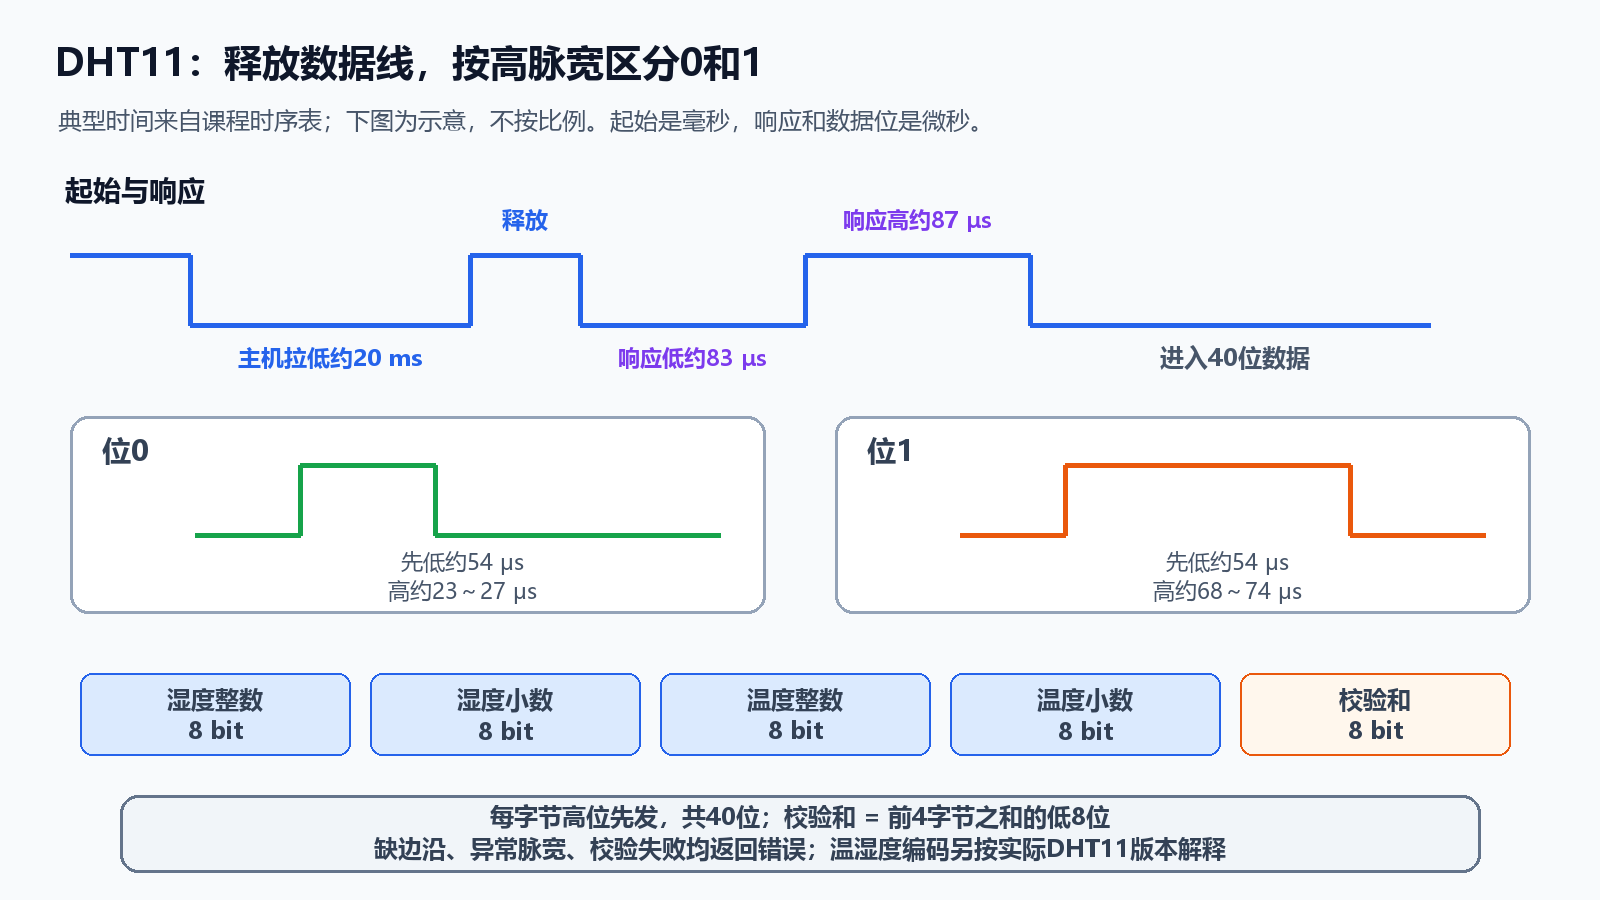

课程可见片段有几个可改进点：`while(count<25)`后判断`count>25`不可能触发，应检查真实期限；响应等待若只等83/87μs，会把合法范围上端也判超时；用循环加1再延时1μs并不保证一次循环恰好1μs。

位接收不应把“高脉宽大于27μs”一律判为1。若噪声得到40μs、线一直高或中断导致漏沿，这不是合法1；先确认两个边沿、脉宽范围，再分类，否则缺失脉冲可能被当数据。

推荐定时器自由运行作微秒时间戳，边沿捕获形成脉宽；是否PB15支持相应定时器捕获，要按复用表确认，也可采用合适的替代引脚/外部中断方案。若用轮询，需评估中断延迟和调度最坏耗时，确保不会跨过短脉冲。

每次边沿等待有上限，整帧也有总预算。主机约20ms的低电平期间可由任务状态机等待，**不要为此关中断20ms**；40位接收约数毫秒，也应优先使用捕获或可证明的时序安排。

短临界区或中断优先级设计服务于可靠采集，但不能影响系统关键业务。普通任务调度和毫秒SysTick分辨率不足以直接测23μs高脉冲，需要适合的硬件计时。


## 27. DHT11帧解析：40位、5字节、低8位和校验

数据高位先发，40位拆成5字节：

```text
byte0 湿度整数 / 高位字段
byte1 湿度小数 / 低位字段
byte2 温度整数 / 高位字段
byte3 温度小数 / 低位字段
byte4 校验和
checksum = (byte0 + byte1 + byte2 + byte3) & 0xFF
```

此处是8位加和校验，**不是CRC**。它能检测很多错误，但两个字段一增一减可能相互抵消；校验通过还需格式、量程和时序检查。

以下独立C99算法只负责将已经捕获的40个高脉宽组装为字节。教学容差窗口设为0:18～35μs、1:55～90μs，留空白区拒绝模糊脉冲；**这些是示例软件策略，不是宣称器件额定时序已扩大**。实际要按具体版本、时基精度和波形验收选窗口，并在外层校验低脉冲与响应阶段。

```c
static bool dht_bit_from_high_us(uint32_t high_us, uint8_t *out)
{
    if (out == NULL) return false;
    if (high_us >= 18u && high_us <= 35u) { *out = 0u; return true; }
    if (high_us >= 55u && high_us <= 90u) { *out = 1u; return true; }
    return false;
}

static bool dht_frame_from_widths(const uint32_t high_us[40],
                                  uint8_t out_frame[5])
{
    if (high_us == NULL || out_frame == NULL) return false;
    uint8_t frame[5] = {0u};
    for (unsigned i = 0; i < 40u; ++i) {
        uint8_t bit;
        if (!dht_bit_from_high_us(high_us[i], &bit)) return false;
        frame[i / 8u] = (uint8_t)((frame[i / 8u] << 1) | bit);
    }
    uint8_t checksum = (uint8_t)((unsigned)frame[0] + frame[1] +
                                  frame[2] + frame[3]);
    if (checksum != frame[4]) return false;
    for (unsigned i = 0; i < 5u; ++i) out_frame[i] = frame[i];
    return true;
}
```

失败时不写输出，避免把半包交给应用；调用者提供真实容量40/5，并记录失败阶段。函数不包括GPIO、边沿获取、响应/低脉冲验证、启动或超时，是**解析算法**。

假设经典整数版格式，`[55,0,24,0,79]`表示55%RH、24°C，校验79。若实际型号支持小数或负温度，温度符号可能在特定低字节位，必须按实际手册解析，不能直接把两字节当有符号16位整数，或把DHT22公式套到DHT11。

课程正文称湿度小数字节为0，而图表对温度小数/符号另有说明，本篇保留这种版本边界。未确认型号时可以显示原始帧并返回格式未确认状态，不能凭猜测发布高精度/负温度。


## 28. 驱动与传感器服务：失败、陈旧和新样本分开

ADC/NTC与DHT11接口不同，但可以向应用发布同样清晰的样本契约。

```c
/* 应用结构示例；同步机制、单位和有效性策略由工程定义。 */
typedef struct {
    float temperature_c;
    float humidity_rh;
    uint32_t acquired_ms;     /* 成功采集完成时刻；不冒充器件内部采样瞬间 */
    uint32_t sequence;
    bool valid;
} app_environment_t;
```

建议另保留最近错误、失败次数、来源、标定版本及原始值。DHT11获取时间可证明本次通信成功时间，未必等于传感器内部真正测量时刻；ADC定时采样则可记录触发时刻与rank偏移。

| 状态 | 应用解释 |
|---|---|
| 新样本且校验/范围通过 | 更新值、采集时刻与序号 |
| 本次通信/采集失败 | 不更新为假值，记录错误 |
| 有上次有效值且未超过陈旧期限 | 可以按业务显示，并标最近更新时间 |
| 超过陈旧期限 | 标陈旧/无效，控制策略按产品要求降级 |
| 断线或超量程 | 独立故障状态，不变成“0°C” |

慢温度业务可将采集、换算、显示分开：DHT11按至少2.1秒节拍取数据，NTC按需要采样并滤波，显示读取一致快照。屏幕刷新不能为了“看起来实时”强制反复请求DHT11。

完整DHT11驱动可以用 `IDLE→START_LOW→WAIT_RESPONSE→CAPTURE_BITS→VERIFY→READY/ERROR` 状态机。错误后释放DATA、等待下一合法请求间隔；重试次数有上限，不用无限阻塞拖住主循环。

跨ISR与任务共享结果时，一次发布完整结构，用原子索引交换、短临界区或适当锁实现一致性；`volatile`不保证温度、湿度、序号和时间戳属于同一次采集。

传感器服务还应考虑第07篇看门狗：按服务状态与允许期限报告进展，不能在永久等待电平或EOC时无条件喂狗掩盖卡死。


## 29. 排错与循序实验：从线路到有效性

| 现象 | 优先检查 | 验证方法 |
|---|---|---|
| ADC一直0 | 供电/共地、模拟模式、引脚与通道、序列首项 | 量输入，接已知合法电压验证 |
| ADC一直4095 | 输入/参考范围、开路/饱和、通道映射 | 同时量节点与参考，不把满码当精确电压 |
| 电压约四倍 | 10位右对齐布局未归一化、分母错误 | 对照原寄存器与数据布局 |
| 读值随前一通道变化 | 源阻抗、建立不足、采样时间 | 延长采样，对比已知低阻源 |
| 多通道值一样 | 结束后反复读同一个RDATA、rank映射 | 单通道基线，再看DMA顺序 |
| 定时采样速率不对 | 连续模式、TIMER/TRGO配置、ADC忙 | 抓触发/完成节拍并检查计数 |
| DMA只搬一轮 | ADC请求持续、DMA循环、计数与映射 | 观察半/全完成和新序号 |
| 温度逆向变化 | NTC上下位置、公式或温度模型符号 | 看实测节点、阻值随升温趋势 |
| NTC边缘温度跳动大 | 近轨敏感度、断线、自热、表范围 | 保留raw，设有效窗口，多点比对 |
| 芯片温度比房间高 | 器件自热、个体偏移、常数错误 | 降负载观察变化，与外部探头比较 |
| DHT11无响应 | 供电/上拉、电平、DATA未释放、起始/间隔 | 抓主机起始与从机响应 |
| DHT11经常校验错 | 漏沿、中断延迟、脉宽窗口、接触/电源 | 保存原始脉宽与帧，核对波形 |
| DHT11偶尔负温/小数怪异 | 型号编码误用、半包或错误帧 | 核对实际手册，先验证40位与校验 |
| 显示稳定但控制反应慢 | 均值/IIR窗口、陈旧数据、采样调度 | 记录原始值与滤波值时间关系 |

实验顺序：

1. 建立供电、参考、引脚与通道表；测合法静态电压。
2. PA0单次采样，转动电位器，记录原始码和节点电压。
3. 分别用长短采样时间、低阻/较高阻源比较，确认建立影响。
4. 逐个验证PA1/内部通道，再按固定rank组成多通道DMA帧。
5. 定时器触发1kHz一轮，核对每路频率、整体转换数与半区节拍。
6. 在不会造成电气损坏的条件下模拟无触发、DMA停搬或探头断线，确认有界失败与恢复。
7. NTC对照实际阻温表/参数，用多个稳定温度点比较，含独立验收点。
8. DHT11抓取起始、响应、40位和校验，检查合法间隔，记录故障帧。
9. 加入滤波、显示与共享任务后重测时序，确认没有跨帧/陈旧数据冒充新值。

保存板号、芯片、SDK、参考值、NTC型号/B或表版本、DHT11版本、引脚、时钟、波形和标定条件。本文这些实验是建议步骤，**尚未上板执行**。


## 30. 自测题与计算练习

1. 12位ADC有多少个码？最大合法码为什么不是4096？
2. 3.3V参考下一个理想12位LSB是多少？分辨率高是否保证温度测量准？
3. code=2048时，除4095与除4096得到的电压各是多少？区别是什么？
4. 为什么数字GPIO的5V容忍不能直接推导出模拟输入可采5V？
5. ADC时钟21MHz，采样144周期，12位一次转换理想多久？
6. 三通道按同样配置每毫秒触发一轮，每路和总结果数分别多少？是否同时采样？
7. 为什么源阻抗大时要增加采样时间？数字平均能否替代建立时间？
8. 10位右对齐结果若在12位区域低2位补0，如何恢复0～1023？
9. rank1、IN1与PA1三个名字分别表示什么？
10. EOCM=0的一轮扫描结束后，读RDATA三次能得到三路结果吗？
11. 只开DMA循环却只搬一轮，ADC端还要检查哪个请求行为？
12. 为什么不能直接遍历一个正在循环写入的DMA数组？
13. 三通道、每半区32帧、32位每项，共多少字节？1kHz帧率下消费窗口约多久？
14. 出现ROVF后为什么要作废当前块并重建DMA/ADC状态？
15. 内部温度是不是室温？VBAT路径读到的量是什么？
16. 上10k固定电阻、下NTC，升温时节点码如何变化？电阻换算公式是什么？
17. NTC换算为什么要拒绝0/4095并检查温区？B模型温度单位是什么？
18. 32个4095求和，用uint16_t够吗？16次理想平均噪声标准差如何变化？
19. 256次12位过采样不移位会怎样？为什么不能照旧用0x0FFF掩码？
20. DHT11 DATA是否需要ADC？与I2C/Dallas 1-Wire是否相同？
21. DHT11响应低典型83μs，是否适合把83μs设为绝对超时上限？
22. 捕获到40μs高脉冲，为什么不能只因大于27μs就当1？
23. `[55,0,24,0,79]`的校验如何算？校验通过能否保证实际格式/范围正确？
24. 本次失败后保留上次值，应用还应保存什么信息？

计算练习：ADC21MHz、3周期采样、12位，理想一次时间；简单10kΩ/100nF RC截止频率；两个10kΩ分压用3.3V时的NTC功耗；用1kHz采样，900Hz干扰可能折叠成多少Hz。


## 31. 参考答案与易错点速查

| 题号 | 参考答案 |
|---|---|
| 1 | 4096个码，编号0～4095；4096是数量 |
| 2 | 3300/4096≈0.805664mV；精度还受参考、电路、噪声、传感器与标定影响 |
| 3 | 端点映射1650.403mV，量化尺度1650.000mV；是不同模型约定 |
| 4 | 数字容忍条件与模拟路径/参考/绝对最大额定不同，要独立核对 |
| 5 | `(144+12)/21MHz≈7.428571μs` |
| 6 | 每路1000SPS，总3000项/秒；rank依次采样，有时刻偏移 |
| 7 | 采样电容建立慢；平均不能修复确定的建立不足偏差 |
| 8 | `(data&0x0FFF)>>2`；先按型号布局归一化 |
| 9 | rank1是第二个序列位置，IN1是模拟通道1，PA1是物理脚 |
| 10 | 不能，旧数据被下一转换覆盖；扫描按要求用DMA及时搬运 |
| 11 | ADC DDM/请求持续，及触发、模式与DMA状态 |
| 12 | 多路/多帧可能属于不同轮；用完成半区和明确时间/所有权 |
| 13 | 2×32×3×4=768字节，每半区约32ms，但ISR/调度会消耗窗口 |
| 14 | 已丢结果且状态/帧相位不可信，不能把半帧继续交付 |
| 15 | 芯片自身温度；VBAT内部路径为VBAT/4，需要乘4恢复 |
| 16 | 温升→R下降→码下降；同源端点约定下R=Rpull×raw/(4095−raw) |
| 17 | 避免除零/无效对数，近轨仍可能故障；B公式用开尔文 |
| 18 | 和131040，超过65535；理想独立噪声平均16次降至1/4 |
| 19 | 和1048320超过16位会截掉高位；输出尺度/位宽已变化 |
| 20 | 不需要，用GPIO脉宽协议；不是I2C或Dallas通用1-Wire |
| 21 | 不适合，合法上限可到88μs，还要计时误差/程序策略 |
| 22 | 课程0范围23～27、1范围68～74，中间异常应拒绝而非强分类 |
| 23 | 前4字节和79取低8位；还需脉冲、型号格式、量程与有效性 |
| 24 | 上次成功时间、序号、有效/陈旧状态及当前错误，不假装新值 |

计算练习答案：3周期采样总15周期，21MHz下 **0.714286μs**；10kΩ/100nF截止约 **159.155Hz**；两10kΩ分压电流165μA，NTC功耗 **0.27225mW**；900Hz在1kHz采样下可折叠为 **100Hz**。

```text
采样率管时间，分辨率管码数；准确度还看参考、前端与标定
采样时间管建立，转换周期管吞吐；扫描是顺序，DMA只搬运
NTC公式看上下位置，B模型用开尔文；滤波不修断线与错误参考
DHT11测脉宽、收40位、验低8位和；失败/陈旧不冒充新样本
```


## 32. 十二篇路线、来源与验证边界

| 序号 | 主题 | 与本篇的关系 |
|---|---|---|
| 01 | C语言核心语法与函数 | 位移、类型、循环、错误返回 |
| 02 | C语言指针与内存 | 数组容量、DMA缓冲与生命周期 |
| 03 | 单片机入门与开发环境 | 芯片/SDK、下载与调试 |
| 04 | GPIO与基础外设控制 | 模拟脚、开漏、实际电平读取 |
| 05 | 中断与定时器 | 采样节拍、边沿捕获、单调超时 |
| 06 | 串口、DMA与通信模块 | DMA映射、宽度、循环与通知 |
| 07 | 实时时钟与系统管理 | 时间有效性、看门狗监督 |
| 08 | I2C与SPI通信 | 数字传感器接口、事务与驱动分层 |
| **09** | **ADC与传感器采集** | **本篇：模拟采集、温度换算、DHT11** |
| 10 | 存储器与文件系统 | 存标定参数与采样记录 |
| 11 | 屏幕显示与触摸驱动 | 显示采集值、状态与趋势 |
| 12 | LVGL图形界面开发 | 界面任务与采集服务解耦 |

已阅读课程页面：

- [GD32F4之ADC查询](https://www.yuque.com/xxcls/mcu/wkcl7m7e9ugazt1g)
- [ADC](https://www.yuque.com/xxcls/mcu/wnprgih0dwht4axm)
- [ADC系统工作原理](https://www.yuque.com/xxcls/mcu/vpihxas7eugpxe59)
- [ADC开发](https://www.yuque.com/xxcls/mcu/ix33hmf5myue5sgb)
- [练习-热敏电阻](https://www.yuque.com/xxcls/mcu/lcrf18yizbu6tyie)
- [温湿度传感器DHT11](https://www.yuque.com/xxcls/mcu/soqt7rpqhnap0poq)

官方核对依据：[GD32F4xx User Manual 3.4](https://gd32mcu.com/download/down/document_id/98/path_type/1)。已读取ADC相关PDF页码 **276～306**，其中 **278、283、284、287** 页图文视觉核对，覆盖模块结构、对齐、采样/触发与过采样。NTC分压图和DHT11接线/时序表在课程页面视觉核对，网页图中文字识别的错字不直接当作单位依据。

本篇没有完整核验具体NTC阻温表/B参数、DHT11独立型号手册、GD32F407的全部模拟电气参数、SDK完整工程与所有长代码编辑器。示例参数、脉宽容差、B模型、滤波、结构体与驱动流程为学习补充；落实到实物前须匹配器件资料与波形。

生成后电脑检查包括：notebook结构、连续章节、代码围栏、3张内嵌PNG、来源及测试边界；独立复核12位换算与整数均值、对齐布局、ADC时间/RC/功耗、NTC阻温模型与插值、DMA索引/半区预算、DHT11高位组帧与校验、回卷计时，并确认既有笔记未改动。

**文档/算法复核不等于 C/SPL 编译或硬件测量。** 本篇未编译SDK示例，未烧录或上板运行，未测输入电压、参考、波形、噪声和温度误差。真正可用性需用第29节的步骤在实际板子验收。
